# TP XGBoost

On va utiliser un vrai jeu de données assez volumineux : `nycflights13::flights` (environ 336 000 vols domestiques américains de 2013). Pour garder des temps d'exécution raisonnable, on n'utilisera que 50 000 vols.

**Objectif** : Prédire si un vol arrive avec un retard de plus de 15 minutes.

In [ ]:
library(dplyr)
library(nycflights13)
library(xgboost)
library(pROC)
library(gbm)
library(knitr)

## Prétraitement des données

Création de la variable cible `retard` qui vaut 1 si le retard à l'arrivée est strictement supérieur à 15 minutes et 0 sinon.

In [45]:
data(flights)

set.seed(123)
flights_clean <- flights |>
  filter(!is.na(arr_delay), !is.na(dep_delay), !is.na(air_time)) |>
  mutate(retard = ifelse(arr_delay > 15, 1, 0),
         carrier = factor(carrier),
         origin = factor(origin)) |>
  select(retard, dep_delay, air_time, distance, month, day, hour, minute, carrier, origin) |> 
  sample_n(50000)

n <- nrow(flights_clean)
prop <- round(mean(flights_clean$retard), 4)

cat("Proportion de vols en retard :", prop * 100, "%")

# carrier et origin sont des variables catégorielles : on les encode en indicatrices (one-hot) puisque xgboost n'accepte que des données numériques.
dummies <- caret::dummyVars(retard ~ ., data = flights_clean, fullRank = TRUE)

Proportion de vols en retard : 23.86 %

## Séparation des données en deux échantillons train et test

In [46]:
set.seed(123)
idx <- as.vector(caret::createDataPartition(factor(flights_clean$retard), p = 0.70, list = FALSE))

train_flights <- flights_clean[idx, ]
test_flights <- flights_clean[-idx, ]

cat("Proportion de vols en retard sur les données d'entrainement :", round(mean(train_flights$retard), 4) * 100, "%\n")
cat("Proportion de vols en retard sur les données de test :", round(mean(test_flights$retard), 4) * 100, "%")

X_train <- predict(dummies, newdata = train_flights)
y_train <- train_flights$retard
X_test <- predict(dummies, newdata = test_flights)
y_test <- test_flights$retard

Proportion de vols en retard sur les données d'entrainement : 23.86 %
Proportion de vols en retard sur les données de test : 23.85 %

**Question** : Pourquoi est-ce qu'on s'assure qu'il y ait la même proportion de retard dans le train et le test ?

<details>
<summary>Voir la réponse</summary>

On utilise un tirage stratifié (`createDataPartition` sur la variable `retard`) plutôt qu'un tirage purement aléatoire pour que le train et le test aient la même proportion de vols en retard (~24%).

Sans cette précaution, un tirage aléatoire pourrait donner par hasard un test set avec une proportion de retards assez différente de celle du train, surtout que la classe "retard" est minoritaire. Cela rendrait les métriques de performance (AUC, accuracy) moins fiables et plus difficiles à comparer d'une exécution à l'autre, puisqu'une partie de la variation observée viendrait du déséquilibre entre train et test plutôt que de la qualité du modèle lui-même.

</details>

## Premier modèle XGBoost (avec paramètres fixés)

Entraînement d'un premier modèle de classification binaire, en suivant l'AUC comme métrique, avec un taux d'apprentissage de 0.1 et 100 arbres.

In [50]:
nb_coeurs <- parallel::detectCores()

In [47]:
boost_1 <- xgboost(data = X_train,
                   label = y_train,
                   nrounds = 100,
                   verbose = 0,
                   params = list(tree_method = "hist",
                                 objective = "binary:logistic",
                                 eval_metric = "auc",
                                 eta = 0.1,
                                 nthread = nb_coeurs - 1))

boost_1

##### xgb.Booster
raw: 385.8 Kb 
call:
  xgb.train(params = params, data = dtrain, nrounds = nrounds, 
    watchlist = watchlist, verbose = verbose, print_every_n = print_every_n, 
    early_stopping_rounds = early_stopping_rounds, maximize = maximize, 
    save_period = save_period, save_name = save_name, xgb_model = xgb_model, 
    callbacks = callbacks)
params (as set within xgb.train):
  tree_method = "hist", objective = "binary:logistic", eval_metric = "auc", eta = "0.1", nthread = "11", validate_parameters = "TRUE"
xgb.attributes:
  niter
callbacks:
  cb.evaluation.log()
# of features: 24 
niter: 100
nfeatures : 24 
evaluation_log:
  iter train_auc
 <num>     <num>
     1 0.9119380
     2 0.9133363
   ---       ---
    99 0.9645810
   100 0.9646649

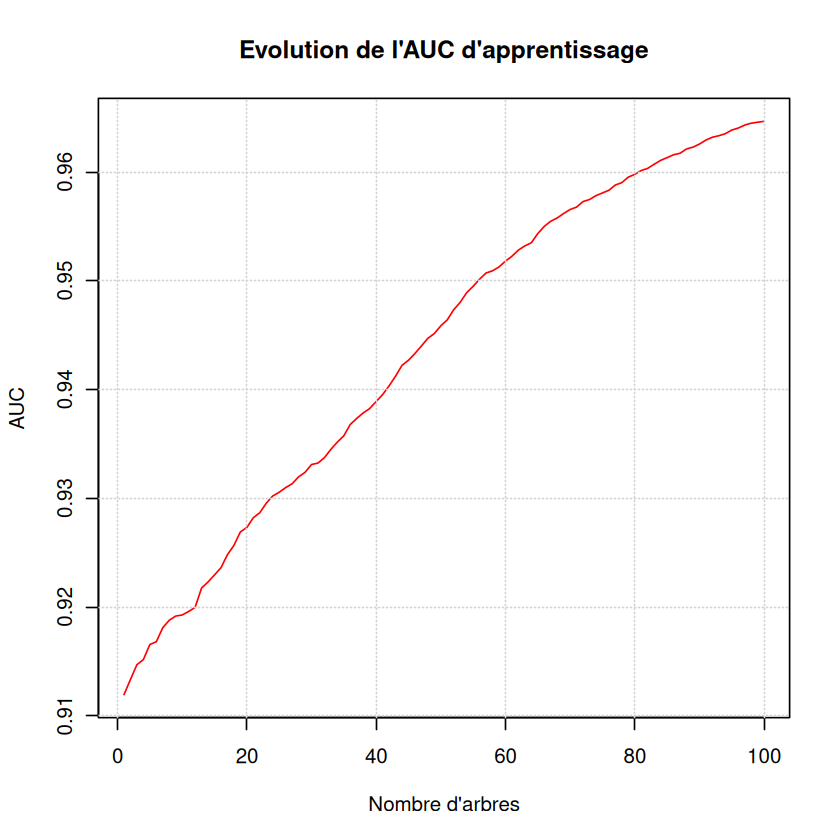

In [31]:
plot(boost_1$evaluation_log,
     xlab = "Nombre d'arbres",
     ylab = "AUC",
     main = "Evolution de l'AUC d'apprentissage",
     col = "red",
     type = "l")
grid(nx = NULL, ny = NULL, col = "lightgray")

**Question** : D'après le graphique ci-dessus, comment évalue l'AUC d'apprentissage lorsque le nombre d'arbre augmente ? Cette AUC mesuré sur les données d'apprentissage permet-elle de conclure sur la qualité du modèle sur de nouvelles données ?

<details>
<summary>Voir la réponse</summary>

Le `evaluation_log` montre l'AUC d'apprentissage passer d'environ 0.91 pour 1 arbre à environ 0.96 pour 100 arbres : le modèle apprend progressivement.

Cette AUC est mesurée sur l'apprentissage donc il peut y avoir du surapprentissage. On va donc faire une validation croisée pour choisir le bon nombre d'arbre.

</details>

## Sélection du nombre d'itération (nombre d'arbres) par validation croisée

In [48]:
X_mat <- xgb.DMatrix(X_train, label = y_train)

sel_xgb <- xgb.cv(data = X_mat,
                  tree_method = "hist",
                  params = list(objective = "binary:logistic",
                                eta = 0.1,
                                nthread = nb_coeurs - 1),
                  nrounds = 300,
                  metrics = "auc",
                  nfold = 10,
                  early_stopping_rounds = 10,
                  verbose = 0)

sel_xgb$evaluation_log |> head()
(ite_opt_demo <- sel_xgb$best_iteration)
sel_xgb$niter

iter,train_auc_mean,train_auc_std,test_auc_mean,test_auc_std
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.9116135,0.0015628014,0.9082427,0.008307432
2,0.9138260,0.0014819049,0.9106028,0.008241218
3,0.9152164,0.0006170255,0.9109789,0.008463098
4,0.9162800,0.0007460488,0.9120713,0.008338874
5,0.9174859,0.0007147925,0.9128025,0.008217975
6,0.9181796,0.0007769402,0.9136135,0.008026948


[1] 262

[1] 272

**Question** : Que représente l'objet `ite_opt_demo` ? Pourquoi peut-il être inférieur à 300 ?

<details>
<summary>Voir la réponse</summary>

`ite_opt_demo` représente le nombre d'arbres optimal (meilleure itération) sélectionné par validation croisée pour la profondeur par défaut : c'est l'itération à laquelle l'AUC moyenne de test (sur les folds de la CV) est maximale.

Il peut être inférieur à 300 car on utilise `early_stopping_rounds = 10` : la validation croisée arrête l'entraînement dès que l'AUC de test ne s'améliore plus pendant 10 itérations consécutives, ce qui évite de continuer à ajouter des arbres inutiles (et donc de surapprendre).

</details>

### Validation croisée sur le nombre d'arbres et la profondeur

In [51]:
profondeurs <- c(2, 3, 4, 6, 8)

resultats_depth <- do.call(rbind, lapply(profondeurs, function(d) {
  cv_d <- xgb.cv(data = X_mat,
                 tree_method = "hist",
                 params = list(objective = "binary:logistic",
                               eta = 0.1,
                               max_depth = d,
                               nthread = nb_coeurs - 1),
                 nrounds = 300,
                 metrics = "auc",
                 nfold = 10,
                 early_stopping_rounds = 10,
                 verbose = 0)

  data.frame(max_depth = d,
             nrounds_opt = cv_d$best_iteration,
             auc_cv = cv_d$evaluation_log$test_auc_mean[cv_d$best_iteration])
}))

resultats_depth

meilleur <- resultats_depth[which.max(resultats_depth$auc_cv), ]
profondeur_opt <- meilleur$max_depth
ite_opt <- meilleur$nrounds_opt

cat("Profondeur optimale :", profondeur_opt,
    "- Nombre d'arbres optimal :", ite_opt,
    "- AUC CV :", round(meilleur$auc_cv, 4), "\n")

max_depth,nrounds_opt,auc_cv
<dbl>,<int>,<dbl>
2,300,0.9384191
3,300,0.9437350
4,300,0.9474025
6,266,0.9482548
8,182,0.9468215


Profondeur optimale : 6 - Nombre d'arbres optimal : 266 - AUC CV : 0.9483 


Pour faire la validation croisé aussi sur les paramètre `gamma`, `lambda` et `alpha`, c'est le même principe que pour `max_depth`. Il suffit de créer une grille qui prend toutes les combinaisons de (`max_depth`, `gamma`, `lambda`, `alpha`) avec `expand.grid`. Ce n'est pas forcement utile ici car on a déjà une AUC de 0.95 et que le gain apporté par `gamma`, `lambda` et `alpha` est généralement faible. De plus de temps de calcul augmente très rapidement.

## Modèle final et performance sur l'échantillon de test

AUC test : 0.95 
Accuracy test : 0.916 


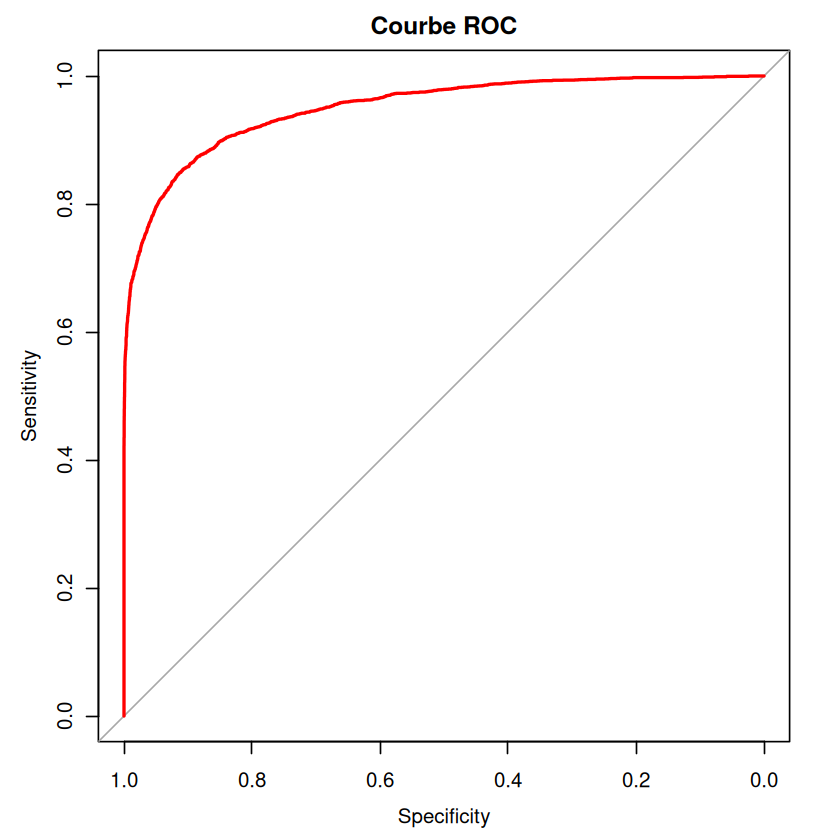

In [40]:
boost_opt <- xgboost(data = X_train,
                     label = y_train,
                     tree_method = "hist",
                     objective = "binary:logistic",
                     eta = 0.1,
                     max_depth = profondeur_opt,
                     nrounds = ite_opt,
                     nthread = nb_coeurs - 1,
                     verbose = 0)

prev_opt <- predict(boost_opt, newdata = X_test)

roc_flights <- roc(y_test, prev_opt, quiet = TRUE)
cat("AUC test :", round(auc(roc_flights), 3), "\n")
cat("Accuracy test :", round(mean((prev_opt > 0.5) == y_test), 3), "\n")

plot(roc_flights,
     main = "Courbe ROC",
     col = "red")

**Question** : Comparer l'AUC de test obtenue ici avec l'AUC d'apprentissage observée précédement. Que pouvez-vous en conclure sur le risque de surapprentissage du premier modèle par rapport au modèle final ?

<details>
<summary>Voir la réponse</summary>

L'AUC d'apprentissage du premier modèle (sans validation croisée, 100 arbres fixés) atteignait environ 0.96-0.965 sur les données d'entraînement elles-mêmes, un chiffre optimiste puisqu'il est mesuré sur les données qui ont servi à ajuster le modèle.

L'AUC obtenue ici sur le jeu de test avec le modèle final (profondeur et nombre d'arbres choisis par CV) est de 0.95, très proche de l'AUC de validation croisée trouvée précédemment (0.948). Le fait que l'AUC de test soit proche de l'AUC de CV, et nettement inférieure à l'AUC d'apprentissage brute du premier modèle, montre que la validation croisée a permis de choisir des hyperparamètres qui limitent le surapprentissage : le modèle final généralise bien, alors que le premier modèle (100 arbres fixes, sans contrôle de la profondeur ni early stopping) était plus à risque de surapprendre.

</details>

**Question** : L'accuracy calculé ici utilise un seuil de 0.5 pour transformer la probabilité prédite en décision. Ce seuil est-il forcément le plus adapté dans ce contexte ?

<details>
<summary>Voir la réponse</summary>

Non, pas forcément. Le seuil de 0.5 n'a rien de spécial statistiquement : il revient à classer "retard" dès que la probabilité prédite dépasse 50%, ce qui n'est optimal que si les deux types d'erreurs (faux positifs et faux négatifs) ont le même coût et que les classes sont équilibrées.

Ici, seulement environ 24% des vols sont en retard : les classes sont déséquilibrées, donc un seuil de 0.5 peut conduire à prédire rarement la classe minoritaire, même si le modèle discrimine bien (AUC élevée). Le choix du seuil devrait plutôt dépendre du contexte métier : coût d'un faux négatif par rapport à un faux positif, plutôt que de se fier par défaut à l'accuracy avec un seuil à 0.5.

</details>

## Comparaison avec le Gradient boosting

On va comparer la vitesse puis les performances des deux modèles avec les mêmes paramètres.

In [44]:
n_trees <- 300
depth <- 6
learning_rate <- 0.1

time_gbm <- system.time({
  model_gbm <- gbm(
    retard ~ .,
    data = train_flights,
    distribution = "bernoulli",
    n.trees = n_trees,
    interaction.depth = depth,
    shrinkage = learning_rate,
    verbose = 0
  )
})

time_xgb <- system.time({
  model_xgb <- xgb.train(
    data = X_mat,
    tree_method = "hist",
    objective = "binary:logistic",
    nrounds = n_trees,
    max_depth = depth,
    eta = learning_rate,
    nthread = 1,
    verbose = 0
  )
})

time <- data.frame(
  modele = c("gbm", "xgboost"),
  temps_sec = c(time_gbm[["elapsed"]], time_xgb[["elapsed"]])
)
kable(time, digits = 3, caption = "Temps d'entraînement (secondes)")



Table: Temps d'entraînement (secondes)

|modele  | temps_sec|
|:-------|---------:|
|gbm     |    19.129|
|xgboost |     2.719|

**Question** : D'après le tableau ci-dessus, quel algorithme s'entraîne le plus rapidement sur ces données, à hyperparamètres égaux ? Cela correspond-il à ce qui est généralement présenté comme un avantage de XGBoost ?

<details>
<summary>Voir la réponse</summary>

XGBoost s'entraîne nettement plus vite ici (environ 2 secondes contre 8 secondes pour `gbm`, à hyperparamètres identiques), soit un facteur d'environ 4.

Oui, cela correspond à l'un des avantages classiquement mis en avant pour XGBoost : son implémentation est optimisée et parallélisée (ici via `tree_method = "hist"` et l'utilisation de plusieurs cœurs avec `nthread`), alors que `gbm` utilise un algorithme plus classique, séquentiel et mono-thread. C'est l'un des arguments qui a motivé la popularité de XGBoost par rapport aux implémentations plus anciennes de gradient boosting.

</details>



Table: Performance sur le jeu de test

|modele  |   AUC| accuracy|
|:-------|-----:|--------:|
|gbm     | 0.945|    0.914|
|xgboost | 0.950|    0.917|

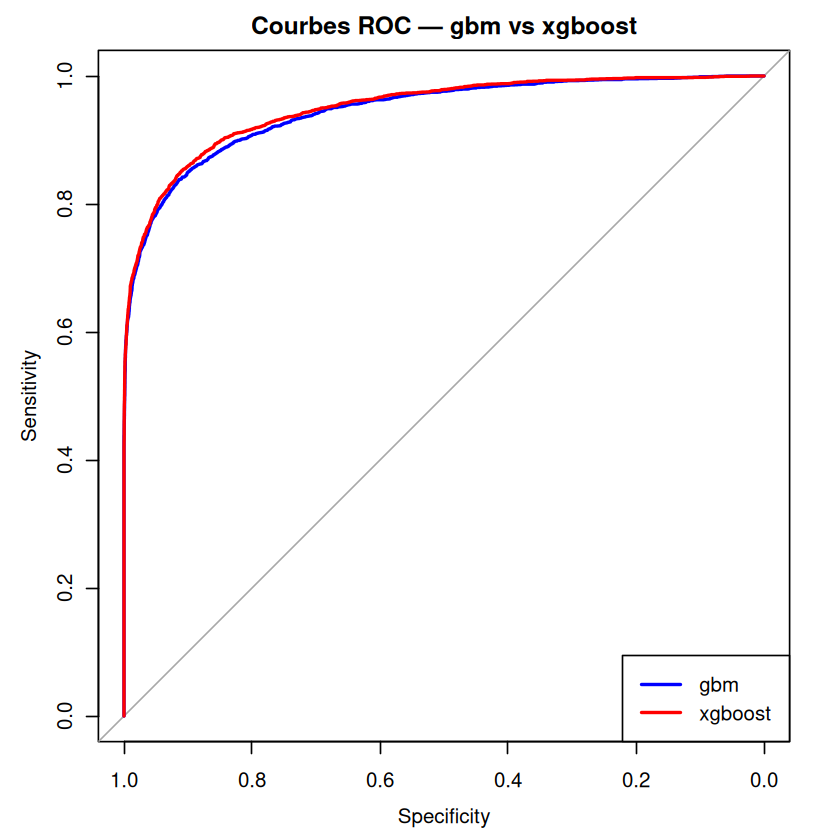

In [37]:
pred_gbm <- predict(model_gbm, newdata = test_flights, n.trees = n_trees, type = "response")
pred_xgb <- predict(model_xgb, newdata = X_test)

roc_gbm <- roc(y_test, pred_gbm, quiet = TRUE)
roc_xgb <- roc(y_test, pred_xgb, quiet = TRUE)

perf <- data.frame(
  modele   = c("gbm", "xgboost"),
  AUC      = c(auc(roc_gbm), auc(roc_xgb)),
  accuracy = c(
    mean((pred_gbm > 0.5) == y_test),
    mean((pred_xgb > 0.5) == y_test)
  )
)
kable(perf, digits = 3, caption = "Performance sur le jeu de test")

plot(roc_gbm, col = "blue", main = "Courbes ROC — gbm vs xgboost")
lines(roc_xgb, col = "red")
legend("bottomright", legend = c("gbm", "xgboost"), col = c("blue", "red"), lwd = 2)

**Question** : Comparez l'AUC et l'accuracy des deux modèles sur le jeu de test. Les différences observées sont-elles importantes ? Ce résultat signifie-t-il que XGBoost sera toujours plus performant que le Gradient Boosting classique, sur n'importe quel jeu de données ?

<details>
<summary>Voir la réponse</summary>

Sur le jeu de test, on obtient AUC = 0.945 et accuracy = 0.914 pour `gbm`, contre AUC = 0.950 et accuracy = 0.917 pour `xgboost`. Les écarts sont faibles (0.005 point d'AUC, 0.003 point d'accuracy) et probablement peu significatifs en pratique : ils entrent dans la variabilité qu'on peut observer entre deux exécutions ou deux échantillonnages différents.

Non, ce résultat ne permet pas de conclure que XGBoost sera toujours plus performant que le Gradient Boosting classique. Ici, les deux modèles ont été entraînés avec exactement les mêmes hyperparamètres, sans réglage spécifique à chaque algorithme, et sur un seul jeu de données. Les performances prédictives dépendent fortement des données, du réglage des hyperparamètres propres à chaque méthode et de la régularisation choisie : sur d'autres jeux de données, ou avec un réglage plus poussé de `gbm`, les résultats pourraient être différents, voire inversés. L'avantage de XGBoost tient surtout à des aspects pratiques (vitesse, gestion native des valeurs manquantes, régularisation intégrée, flexibilité) plutôt qu'à une supériorité garantie en termes de pouvoir prédictif brut.

</details>